# Phase 1 · EDA & Problem Formulation
### Khám phá dữ liệu và chứng minh bản chất của bài toán phát hiện Phishing URL

| 5W1H | Nội dung |
|---|---|
| **What** | Hiểu cấu trúc, chất lượng và phân phối của tập `phishing_site_urls.csv`, đồng thời **chứng minh bằng số liệu** rằng ranh giới giữa URL hợp lệ và URL phishing là **phi tuyến**. |
| **Why** | Mọi lựa chọn ở các phase sau (làm sạch, chia tập, đặc trưng, thuật toán, metric) phải xuất phát từ **bằng chứng dữ liệu**, không xuất phát từ thói quen. |
| **Who** | Principal ML Engineer / Cybersecurity Data Scientist. |
| **Where** | Đầu vào: `data/raw/phishing_site_urls.csv` (giữ đúng đường dẫn của code cũ). Đầu ra: `artifacts/reports/phase1_*.{csv,json}`. |
| **When** | Phase đầu tiên trong chuỗi 4 notebook. Notebook này **chỉ quan sát và kiểm định**, không huấn luyện mô hình cuối cùng. |
| **How** | Data dictionary → kiểm toán chất lượng → thống kê mô tả (variance, IQR, skewness, kurtosis) → 5 bằng chứng phi tuyến → suy luận 5-Whys ra họ thuật toán. |

> **Quy ước chống rò rỉ:** notebook này chưa chia train/test, nên mọi kiểm định dùng **mẫu con** và **cross-validation theo domain**. Mục tiêu ở đây là hiểu dữ liệu, không phải đo hiệu năng cuối cùng.

## 0. Thiết lập môi trường
Thư mục gốc dự án được dò tự động, nên notebook chạy được dù Jupyter khởi động ở thư mục gốc hay ở `notebooks_new/`. Logic dùng chung (chuẩn hóa URL, entropy, tách domain) được import từ `src/phishing_ml/`, là module mới. Code cũ trong `src/features/` giữ nguyên.

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path


def _find_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data' / 'raw' / 'phishing_site_urls.csv').exists():
            return p
    raise FileNotFoundError('Không tìm thấy thư mục gốc dự án.')


ROOT = _find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import log_loss, roc_auc_score, average_precision_score

from src.phishing_ml.config import RAW_PATH, REPORT_DIR, RANDOM_STATE, PALETTE, ensure_dirs, seed_everything
from src.phishing_ml.features import normalize_url, split_components, host_parts, shannon_entropy

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
seed_everything()
ensure_dirs()
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
pd.set_option('display.max_columns', 40)

SAMPLE_N = 60_000        # mẫu con cho các kiểm định tốn kém (LRT, CV, PCA)
TSNE_N = 6_000           # mẫu cho t-SNE
print(f'Project root: {ROOT}')
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}')

Project root: /Users/buiquanghuy/Documents/phishing-url-detection
Python 3.14.4 | pandas 3.1.1 | numpy 2.5.5


## 1. Tải dữ liệu gốc và Data Dictionary

Đường dẫn được giữ nguyên như notebook cũ (`data/raw/phishing_site_urls.csv`, dataset Kaggle *Phishing Site URLs*). Dữ liệu thô **chỉ có 2 cột**. Toàn bộ thông tin dự đoán phải được **trích xuất từ chính chuỗi URL**. Đây là đặc điểm định hình cả pipeline.

In [2]:
raw = pd.read_csv(RAW_PATH)
print(f'Kích thước: {raw.shape[0]:,} dòng × {raw.shape[1]} cột | Bộ nhớ: {raw.memory_usage(deep=True).sum() / 1e6:.1f} MB')
display(raw.head(8))
display(raw.dtypes.to_frame('dtype (pandas)'))

Kích thước: 549,346 dòng × 2 cột | Bộ nhớ: 38.7 MB


,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad
5,smilesvoegol.servebbs.org/voegol.php,bad
6,premierpaymentprocessing.com/includes/boleto-2...,bad
7,myxxxcollection.com/v1/js/jih321/bpd.com.do/do...,bad


,dtype (pandas)
URL,str
Label,str


Để lập data dictionary đầy đủ, ta tạo thêm các **trường dẫn xuất** sẽ dùng ở các phase sau: nhãn số, URL chuẩn hóa, host, registered domain, TLD. Chúng được tính bằng chính các hàm trong `src/phishing_ml/features.py`, là các hàm sẽ chạy ở inference. Nhờ vậy những gì ta khám phá ở đây khớp với những gì mô hình sẽ thấy.

In [3]:
t0 = time.time()
df_raw = raw.rename(columns={'URL': 'url', 'Label': 'label_text'}).copy()
df_raw['label'] = df_raw['label_text'].map({'bad': 1, 'good': 0})
df_raw['url_norm'] = df_raw['url'].astype(str).map(normalize_url)

comps = [split_components(u) for u in df_raw['url_norm']]
df_raw['host'] = [c[0] for c in comps]
df_raw['path'] = [c[3] for c in comps]
df_raw['query'] = [c[4] for c in comps]
host_info = {h: host_parts(h) for h in df_raw['host'].unique()}
df_raw['registered_domain'] = df_raw['host'].map(lambda h: host_info[h][3])
df_raw['tld'] = df_raw['host'].map(lambda h: host_info[h][2] or '<none>')
print(f'Tạo trường dẫn xuất trong {time.time() - t0:.1f}s ({len(host_info):,} host duy nhất)')


def describe_field(name, series, dtype_logic, role, desc):
    s = series
    return {'Trường': name, 'Kiểu (pandas)': str(s.dtype), 'Kiểu logic': dtype_logic, 'Vai trò': role,
            'Mô tả': desc, 'Ví dụ': str(s.dropna().iloc[0])[:45], 'Số giá trị khác nhau': s.nunique(),
            '% thiếu': s.isna().mean() * 100}


data_dictionary = pd.DataFrame([
    describe_field('URL', raw['URL'], 'Chuỗi tự do (≤ vài nghìn ký tự)', 'Đầu vào gốc',
                   'URL thô, phần lớn không có scheme http(s)://'),
    describe_field('Label', raw['Label'], 'Phân loại nhị phân', 'Nhãn gốc',
                   "'bad' = phishing/độc hại, 'good' = hợp lệ"),
    describe_field('label', df_raw['label'], 'Nhị phân {0,1}', 'Biến mục tiêu',
                   'Mã hóa: bad → 1 (lớp dương), good → 0'),
    describe_field('url_norm', df_raw['url_norm'], 'Chuỗi', 'Dẫn xuất (đầu vào TF-IDF)',
                   'URL chuẩn hóa: bỏ scheme, www., `/` cuối; host viết thường'),
    describe_field('host', df_raw['host'], 'Chuỗi', 'Dẫn xuất',
                   'Hostname (không gồm userinfo, port)'),
    describe_field('registered_domain', df_raw['registered_domain'], 'Phân loại (lực lượng rất lớn)',
                   'Khóa nhóm (chia tập)', 'Domain đăng ký theo Public Suffix List (eTLD+1)'),
    describe_field('tld', df_raw['tld'], 'Phân loại (lực lượng lớn)', 'Đặc trưng phân loại',
                   'Hậu tố công khai, ví dụ com, co.uk, ru'),
])
display(data_dictionary)
data_dictionary.to_csv(REPORT_DIR / 'phase1_data_dictionary.csv', index=False)

Tạo trường dẫn xuất trong 4.0s (187,612 host duy nhất)


,Trường,Kiểu (pandas),Kiểu logic,Vai trò,Mô tả,Ví dụ,Số giá trị khác nhau,% thiếu
0,URL,str,Chuỗi tự do (≤ vài nghìn ký tự),Đầu vào gốc,"URL thô, phần lớn không có scheme http(s)://",nobell.it/70ffb52d079109dca5664cce6f317373782,507195,0.0000
1,Label,str,Phân loại nhị phân,Nhãn gốc,"'bad' = phishing/độc hại, 'good' = hợp lệ",bad,2,0.0000
2,label,int64,"Nhị phân {0,1}",Biến mục tiêu,"Mã hóa: bad → 1 (lớp dương), good → 0",1,2,0.0000
3,url_norm,str,Chuỗi,Dẫn xuất (đầu vào TF-IDF),"URL chuẩn hóa: bỏ scheme, www., `/` cuối; host...",nobell.it/70ffb52d079109dca5664cce6f317373782,501552,0.0000
4,host,str,Chuỗi,Dẫn xuất,"Hostname (không gồm userinfo, port)",nobell.it,187612,0.0000
5,registered_domain,str,Phân loại (lực lượng rất lớn),Khóa nhóm (chia tập),Domain đăng ký theo Public Suffix List (eTLD+1),nobell.it,151536,0.0000
6,tld,str,Phân loại (lực lượng lớn),Đặc trưng phân loại,"Hậu tố công khai, ví dụ com, co.uk, ru",it,810,0.0000


### 1.1. Vì sao bài toán và dữ liệu này phù hợp với Machine Learning? (5-Whys)

| # | Câu hỏi "Tại sao?" | Trả lời dựa trên dữ liệu và bối cảnh |
|:-:|---|---|
| 1 | Tại sao không dùng **blacklist**? | Phishing kit sinh URL mới cho từng chiến dịch, thậm chí cho từng nạn nhân. Blacklist chỉ chặn được URL đã biết, nên **không bắt được zero-day**. |
| 2 | Tại sao không dùng **luật thủ công** (regex, từ khóa)? | Một từ khóa như `login` hay `paypal` vừa xuất hiện ở site hợp lệ vừa xuất hiện ở site giả. Nhãn phụ thuộc vào **tổ hợp** nhiều tín hiệu yếu (vị trí từ khóa, TLD, entropy…), và số tổ hợp tăng theo cấp số nhân. Viết luật tay không theo kịp. |
| 3 | Tại sao dữ liệu này **học được**? | Có hơn 500 nghìn URL **đã gán nhãn**, là bài toán phân loại nhị phân có giám sát chuẩn mực. Các mục 3–5 dưới đây chứng minh rằng **cấu trúc chuỗi URL mang tín hiệu thống kê** có ý nghĩa: phân phối hai lớp khác nhau với p-value ≈ 0 và effect size đáng kể. |
| 4 | Tại sao chỉ dùng **chuỗi URL** là đủ? | Đặc trưng lexical tính được **offline, dưới 1 ms/URL**, không cần truy vấn mạng (WHOIS/DNS). Điều này phù hợp với kịch bản chặn real-time ở proxy hoặc email gateway, và code cũ đã thất bại khi dùng WHOIS (đặc trưng hằng −1). |
| 5 | Tại sao cần ML **có kiểm soát rò rỉ**? | Một domain lớn có hàng nghìn URL (`wikipedia.org`…). Nếu mô hình "nhớ domain" thì sẽ không phát hiện được domain mới. Vì vậy bài toán phải được đánh giá trên **domain chưa thấy**, và Phase 2 sẽ hiện thực điều này. |

## 2. Kiểm toán chất lượng dữ liệu (Data Quality Audit)

Kiểm tra năm loại vấn đề kinh điển: giá trị thiếu, trùng lặp chính xác, **trùng lặp gần** (chỉ lộ ra sau chuẩn hóa), **mâu thuẫn nhãn**, và **thiên lệch định dạng** có thể tạo shortcut.

In [4]:
n_raw = len(df_raw)
exact_dup = df_raw.duplicated(subset='url').sum()
norm_dup = df_raw.duplicated(subset='url_norm').sum()
conflict_exact = (df_raw.groupby('url')['label'].nunique() > 1).sum()
conflict_norm = (df_raw.groupby('url_norm')['label'].nunique() > 1).sum()
has_scheme = df_raw['url'].str.match(r'^[A-Za-z][A-Za-z0-9+.\-]*://').mean()

quality = pd.DataFrame({
    'Kiểm tra': ['Số dòng thô', 'Giá trị thiếu (URL hoặc Label)', 'Trùng lặp chính xác theo chuỗi URL',
                 'Trùng lặp sau chuẩn hóa (gồm cả bản chính xác)', 'URL thô có nhãn mâu thuẫn',
                 'URL chuẩn hóa có nhãn mâu thuẫn', 'Tỉ lệ URL có scheme http(s)://',
                 'URL rỗng sau chuẩn hóa'],
    'Giá trị': [f'{n_raw:,}', f'{int(raw.isna().any(axis=1).sum()):,}', f'{exact_dup:,} ({exact_dup / n_raw:.2%})',
                f'{norm_dup:,} ({norm_dup / n_raw:.2%})', f'{conflict_exact:,}', f'{conflict_norm:,}',
                f'{has_scheme:.3%}', f'{(df_raw["url_norm"].str.len() == 0).sum():,}'],
})
display(quality)

,Kiểm tra,Giá trị
0,Số dòng thô,"549,346"
1,Giá trị thiếu (URL hoặc Label),0
2,Trùng lặp chính xác theo chuỗi URL,"42,151 (7.67%)"
3,Trùng lặp sau chuẩn hóa (gồm cả bản chính xác),"47,794 (8.70%)"
4,URL thô có nhãn mâu thuẫn,1
5,URL chuẩn hóa có nhãn mâu thuẫn,2
6,Tỉ lệ URL có scheme http(s)://,0.023%
7,URL rỗng sau chuẩn hóa,0


**Thiên lệch định dạng (shortcut).** Code cũ không chuẩn hóa URL, nên mô hình học được quy tắc giả "URL không có `/` ⇒ phishing". Bảng dưới so sánh tỉ lệ phishing của một số mẫu hình **trước** chuẩn hóa (chuỗi thô) và **sau** chuẩn hóa.

In [5]:
base_rate = df_raw['label'].mean()
patterns = {
    'Không chứa "/" (domain trần)': (~df_raw['url'].str.contains('/', regex=False),
                                     ~df_raw['url_norm'].str.contains('/', regex=False)),
    'Kết thúc bằng "/"': (df_raw['url'].str.endswith('/'), df_raw['url_norm'].str.endswith('/')),
    'Bắt đầu bằng "www."': (df_raw['url'].str.lower().str.startswith('www.'),
                            df_raw['url_norm'].str.startswith('www.')),
    'Có chữ in hoa': (df_raw['url'].str.contains(r'[A-Z]'), df_raw['url_norm'].str.contains(r'[A-Z]')),
}
rows = []
for name, (m_raw, m_norm) in patterns.items():
    rows.append({'Mẫu hình': name,
                 'Số URL (thô)': int(m_raw.sum()),
                 'P(phishing) thô': df_raw.loc[m_raw, 'label'].mean() if m_raw.any() else np.nan,
                 'Số URL (chuẩn hóa)': int(m_norm.sum()),
                 'P(phishing) chuẩn hóa': df_raw.loc[m_norm, 'label'].mean() if m_norm.any() else np.nan})
shortcut = pd.DataFrame(rows)
print(f'Tỉ lệ phishing nền trên dữ liệu thô (còn trùng lặp): {base_rate:.4f}')
display(shortcut)

Tỉ lệ phishing nền trên dữ liệu thô (còn trùng lặp): 0.2847


,Mẫu hình,Số URL (thô),P(phishing) thô,Số URL (chuẩn hóa),P(phishing) chuẩn hóa
0,"Không chứa ""/"" (domain trần)",4499,0.9860,58143,0.2435
1,"Kết thúc bằng ""/""",146209,0.2600,0,NaN
2,"Bắt đầu bằng ""www.""",47661,0.3675,5,1.0000
3,Có chữ in hoa,168504,0.2261,168324,0.2255


### 2.1. Bộ dữ liệu "canonical" dùng để khám phá

Để thống kê không bị đếm trùng, phần khám phá từ đây trở đi dùng tập **sau chuẩn hóa, khử trùng lặp, loại nhãn mâu thuẫn**, giống quy trình chính thức của Phase 2. Phase 2 sẽ thực hiện lại bước này và lưu kết quả xuống đĩa. Ở đây ta chỉ cần nó để quan sát.

Bộ canonical: 501,550 URL | 151,535 registered domain | tỉ lệ mất cân bằng = 3.61 : 1


,Số URL,Tỉ lệ (%)
label,,
Legitimate (0),392869,78.3310
Phishing (1),108681,21.6690


99.8% domain "thuần" (chỉ chứa 1 nhãn) | 20 domain lớn nhất chiếm 16.8% số URL


,n_urls,phishing_rate
registered_domain,,
wikipedia.org,13424,0.0000
youtube.com,8632,0.0000
facebook.com,8337,0.0006
blogspot.com,7862,0.0472
yahoo.com,5808,0.0005
linkedin.com,5025,0.0002
amazon.com,4764,0.0000
imdb.com,3471,0.0000
ietf.org,3212,0.0000


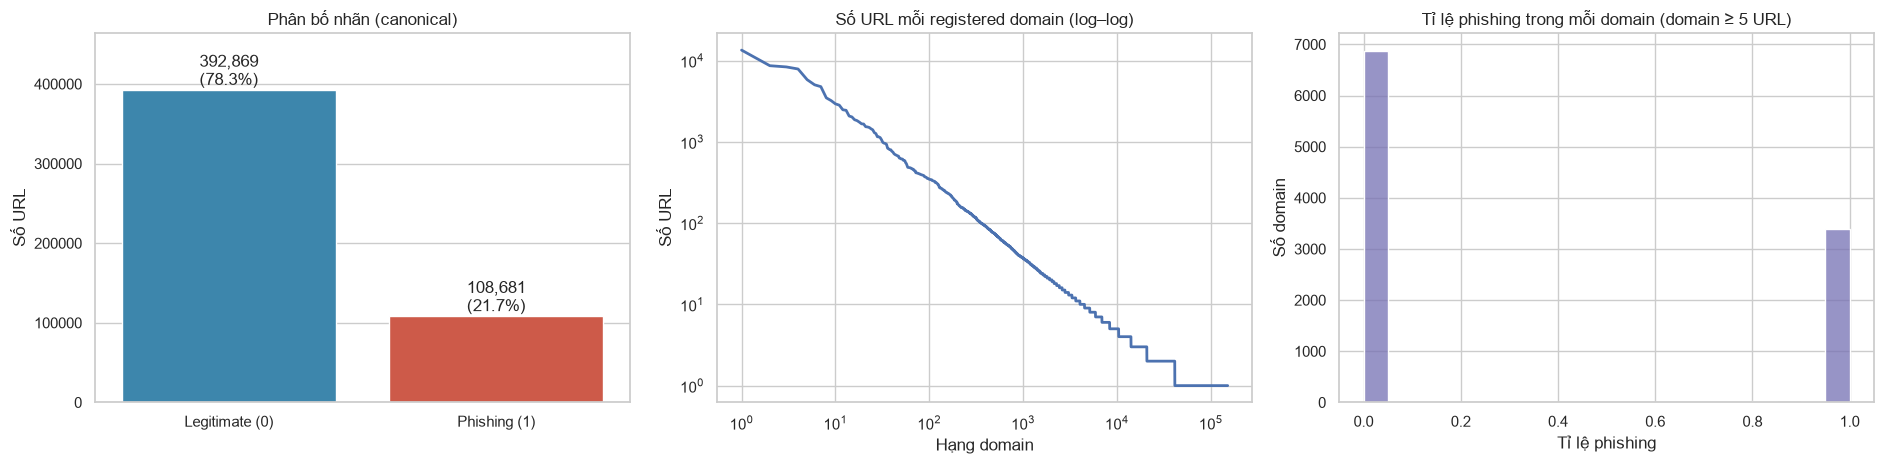

In [6]:
n_labels = df_raw.groupby('url_norm')['label'].transform('nunique')
df = (df_raw[(n_labels == 1) & (df_raw['url_norm'].str.len() > 0)]
      .drop_duplicates(subset='url_norm').reset_index(drop=True))
y = df['label'].to_numpy()

class_tbl = (df['label'].value_counts().rename(index={0: 'Legitimate (0)', 1: 'Phishing (1)'})
             .to_frame('Số URL').assign(**{'Tỉ lệ (%)': lambda t: t['Số URL'] / t['Số URL'].sum() * 100}))
imbalance_ratio = (y == 0).sum() / (y == 1).sum()
print(f'Bộ canonical: {len(df):,} URL | {df["registered_domain"].nunique():,} registered domain | '
      f'tỉ lệ mất cân bằng = {imbalance_ratio:.2f} : 1')
display(class_tbl)

dom = df.groupby('registered_domain')['label'].agg(n_urls='size', phishing_rate='mean')
dom_pure = ((dom['phishing_rate'] == 0) | (dom['phishing_rate'] == 1)).mean()
top_share = dom['n_urls'].sort_values(ascending=False).head(20).sum() / len(df)
print(f'{dom_pure:.1%} domain "thuần" (chỉ chứa 1 nhãn) | 20 domain lớn nhất chiếm {top_share:.1%} số URL')
display(dom.sort_values('n_urls', ascending=False).head(10))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
sns.barplot(x=class_tbl.index, y=class_tbl['Số URL'], hue=class_tbl.index, palette=list(PALETTE.values()),
            legend=False, ax=axes[0])
for i, v in enumerate(class_tbl['Số URL']):
    axes[0].text(i, v, f'{v:,}\n({class_tbl["Tỉ lệ (%)"].iloc[i]:.1f}%)', ha='center', va='bottom')
axes[0].set(title='Phân bố nhãn (canonical)', xlabel='', ylabel='Số URL', ylim=(0, class_tbl['Số URL'].max() * 1.18))

sizes = dom['n_urls'].sort_values(ascending=False).to_numpy()
axes[1].loglog(np.arange(1, len(sizes) + 1), sizes, lw=2)
axes[1].set(title='Số URL mỗi registered domain (log–log)', xlabel='Hạng domain', ylabel='Số URL')

sns.histplot(dom.loc[dom['n_urls'] >= 5, 'phishing_rate'], bins=20, ax=axes[2], color='#7570b3')
axes[2].set(title='Tỉ lệ phishing trong mỗi domain (domain ≥ 5 URL)', xlabel='Tỉ lệ phishing', ylabel='Số domain')
plt.tight_layout()
plt.show()

**Nhận xét: kiểm toán chất lượng và phân bố**

- **Trùng lặp:** có 42,151 dòng (7.67%) trùng chính xác. Sau chuẩn hóa con số này tăng lên 47,794 (8.70%), tức có thêm **khoảng 5,600 bản gần trùng** mà code cũ không phát hiện được (khác nhau ở `www.`, `/` cuối, scheme). Nếu giữ lại, chúng sẽ thổi phồng kết quả khi một bản rơi vào train và bản kia rơi vào test.
- **Train/serve skew:** chỉ **0.023%** URL có scheme, trong khi URL thực tế (trình duyệt, email) luôn có. Chuẩn hóa là bắt buộc.
- **Shortcut đã bị vô hiệu hóa:** URL thô không có `/` có tỉ lệ phishing **98.6%**. Sau chuẩn hóa, nhóm "domain trần" gồm 58,143 URL chỉ còn **24.4%** phishing, xấp xỉ tỉ lệ nền 21.7%. Đặc trưng định dạng không còn mang nhãn, và mô hình buộc phải học tín hiệu thật.
- **Mất cân bằng vừa phải** (3.61 : 1). Không cần sinh dữ liệu nhân tạo, nhưng cần metric và trọng số phù hợp.
- **Cấu trúc nhóm theo domain rất mạnh:** **99.8%** domain chỉ chứa một nhãn, và histogram tỉ lệ phishing theo domain dồn hai cực 0 và 1. Biểu đồ log–log gần như một đường thẳng, tức phân phối **luật lũy thừa** (power-law): 20 domain lớn nhất chiếm 16.8% số URL (`wikipedia.org` có 13,424 URL). **Hệ quả:** nếu chia ngẫu nhiên, mô hình chỉ cần "nhớ domain" là đoán đúng nhãn. Đây là lý do Phase 2 phải chia theo nhóm domain.

## 3. Data Profiling: thống kê mô tả của cấu trúc URL

Vì dữ liệu gốc chỉ có chuỗi, ta định lượng chuỗi bằng **14 bộ mô tả cấu trúc** (structural descriptors). Đây chưa phải bộ đặc trưng cuối cùng (Phase 3 có hơn 60 đặc trưng và TF-IDF n-gram). Mục đích của chúng là **đo độ phân tán và hình dạng phân phối** để định hướng tiền xử lý và chọn thuật toán.

Chỉ số được báo cáo cho mỗi biến: Mean, Std, **Variance**, các phân vị, **IQR**, **Skewness** (độ lệch: |skew| > 1 là lệch mạnh), **Kurtosis** (độ nhọn dư: > 3 là đuôi dày), và % ngoại lai theo quy tắc Tukey (1.5·IQR).

In [7]:
def structural_descriptors(frame: pd.DataFrame) -> pd.DataFrame:
    s, host, path, query = frame['url_norm'], frame['host'], frame['path'], frame['query']
    url_len = s.str.len()
    n_digits = s.str.count(r'\d')
    return pd.DataFrame({
        'url_len': url_len,
        'host_len': host.str.len(),
        'path_len': path.str.len(),
        'query_len': query.str.len(),
        'path_depth': path.str.count(r'/[^/]+'),
        'host_n_dots': host.str.count(r'\.'),
        'n_dots': s.str.count(r'\.'),
        'n_hyphens': s.str.count('-'),
        'n_slashes': s.str.count('/'),
        'n_digits': n_digits,
        'n_special': s.str.count(r'[^A-Za-z0-9]'),
        'digit_ratio': n_digits / url_len.clip(lower=1),
        'url_entropy': s.str.lower().map(shannon_entropy),
        'longest_token': s.str.lower().str.findall(r'[a-z0-9]+').map(lambda t: max(map(len, t), default=0)),
    })


t0 = time.time()
D = structural_descriptors(df)
DESC_COLS = list(D.columns)
print(f'Tính {len(DESC_COLS)} bộ mô tả cho {len(D):,} URL trong {time.time() - t0:.1f}s')


def profile(frame: pd.DataFrame) -> pd.DataFrame:
    q1, med, q3 = frame.quantile(0.25), frame.median(), frame.quantile(0.75)
    iqr = q3 - q1
    out = ((frame < q1 - 1.5 * iqr) | (frame > q3 + 1.5 * iqr)).mean() * 100
    return pd.DataFrame({'Mean': frame.mean(), 'Std': frame.std(), 'Variance': frame.var(), 'Min': frame.min(),
                         'Q1': q1, 'Median': med, 'Q3': q3, 'Max': frame.max(), 'IQR': iqr,
                         'CV (Std/Mean)': frame.std() / frame.mean(), 'Skewness': frame.skew(),
                         'Kurtosis': frame.kurt(), '% ngoại lai (Tukey 1.5)': out})


prof = profile(D)
prof.to_csv(REPORT_DIR / 'phase1_profile.csv')
display(prof.style.format('{:,.3f}')
        .background_gradient(subset=['Skewness', 'Kurtosis', '% ngoại lai (Tukey 1.5)'], cmap='Reds'))

Tính 14 bộ mô tả cho 501,550 URL trong 4.4s


,Mean,Std,Variance,Min,Q1,Median,Q3,Max,IQR,CV (Std/Mean),Skewness,Kurtosis,% ngoại lai (Tukey 1.5)
url_len,50.842,43.029,"1,851.522",1.000,29.000,41.000,60.000,"2,307.000",31.000,0.846,6.407,102.958,5.524
host_len,16.772,11.831,139.966,0.000,12.000,15.000,19.000,244.000,7.000,0.705,8.912,114.396,4.273
path_len,26.839,24.404,595.562,0.000,11.000,21.000,37.000,"2,156.000",26.000,0.909,3.573,130.029,4.147
query_len,7.031,32.160,"1,034.289",0.000,0.000,0.000,0.000,"2,245.000",0.000,4.574,12.048,278.945,15.271
path_depth,2.129,1.561,2.436,0.000,1.000,2.000,3.000,34.000,2.000,0.733,1.471,6.407,1.404
host_n_dots,1.423,1.029,1.059,0.000,1.000,1.000,2.000,34.000,1.000,0.723,7.898,97.596,1.667
n_dots,1.968,1.472,2.168,0.000,1.000,2.000,2.000,37.000,1.000,0.748,5.130,45.432,6.558
n_hyphens,1.202,2.504,6.269,0.000,0.000,0.000,1.000,42.000,1.000,2.084,3.551,18.395,15.555
n_slashes,2.216,1.645,2.705,0.000,1.000,2.000,3.000,35.000,2.000,0.742,1.629,7.376,2.036
n_digits,4.724,11.278,127.195,0.000,0.000,1.000,6.000,545.000,6.000,2.387,7.550,105.183,6.053


### 3.1. So sánh hai lớp: hai phân phối có thực sự khác nhau?

Với n lớn, p-value gần như luôn bằng 0, nên ta báo cáo thêm **effect size** để đo mức khác biệt *thực chất*:
- **Mann–Whitney U** (phi tham số, vì dữ liệu lệch nặng) kèm **Cliff's δ = 2·AUC − 1** ∈ [−1, 1]. |δ| < 0.147 là không đáng kể, < 0.33 là nhỏ, < 0.474 là vừa, còn lại là lớn (ngưỡng Romano et al., 2006).
- **Kolmogorov–Smirnov D**: khoảng cách lớn nhất giữa hai hàm phân phối tích lũy.
- **AUC đơn biến**: mức tách lớp nếu chỉ dùng **riêng** biến đó.

In [8]:
def effect_label(d):
    d = abs(d)
    return 'không đáng kể' if d < 0.147 else 'nhỏ' if d < 0.33 else 'vừa' if d < 0.474 else 'lớn'


rows = []
for c in DESC_COLS:
    a, b = D.loc[y == 1, c], D.loc[y == 0, c]
    u, p_u = stats.mannwhitneyu(a, b, alternative='two-sided')
    auc = u / (len(a) * len(b))
    ks = stats.ks_2samp(a, b)
    rows.append({'Biến': c, 'Median Legit': b.median(), 'Median Phish': a.median(),
                 'Mann-Whitney p': p_u, "Cliff's δ": 2 * auc - 1, 'Mức effect': effect_label(2 * auc - 1),
                 'KS D': ks.statistic, 'AUC đơn biến': max(auc, 1 - auc)})
class_diff = pd.DataFrame(rows).set_index('Biến').sort_values('AUC đơn biến', ascending=False)
class_diff.to_csv(REPORT_DIR / 'phase1_class_difference.csv')
display(class_diff.style.format({'Median Legit': '{:.3f}', 'Median Phish': '{:.3f}', 'Mann-Whitney p': '{:.1e}',
                                 "Cliff's δ": '{:+.3f}', 'KS D': '{:.3f}', 'AUC đơn biến': '{:.3f}'})
        .background_gradient(subset=['AUC đơn biến'], cmap='Greens'))

,Median Legit,Median Phish,Mann-Whitney p,Cliff's δ,Mức effect,KS D,AUC đơn biến
Biến,,,,,,,
n_dots,2.000,2.000,0.0e+00,+0.344,vừa,0.280,0.672
longest_token,10.000,12.000,0.0e+00,+0.210,nhỏ,0.205,0.605
host_len,15.000,16.000,0.0e+00,+0.187,nhỏ,0.133,0.594
n_digits,0.000,2.000,0.0e+00,+0.176,nhỏ,0.185,0.588
n_slashes,2.000,2.000,0.0e+00,+0.176,nhỏ,0.157,0.588
digit_ratio,0.000,0.042,0.0e+00,+0.172,nhỏ,0.141,0.586
url_len,40.000,47.000,0.0e+00,+0.170,nhỏ,0.183,0.585
url_entropy,4.098,4.186,0.0e+00,+0.167,nhỏ,0.184,0.584
query_len,0.000,0.000,0.0e+00,+0.141,không đáng kể,0.153,0.571


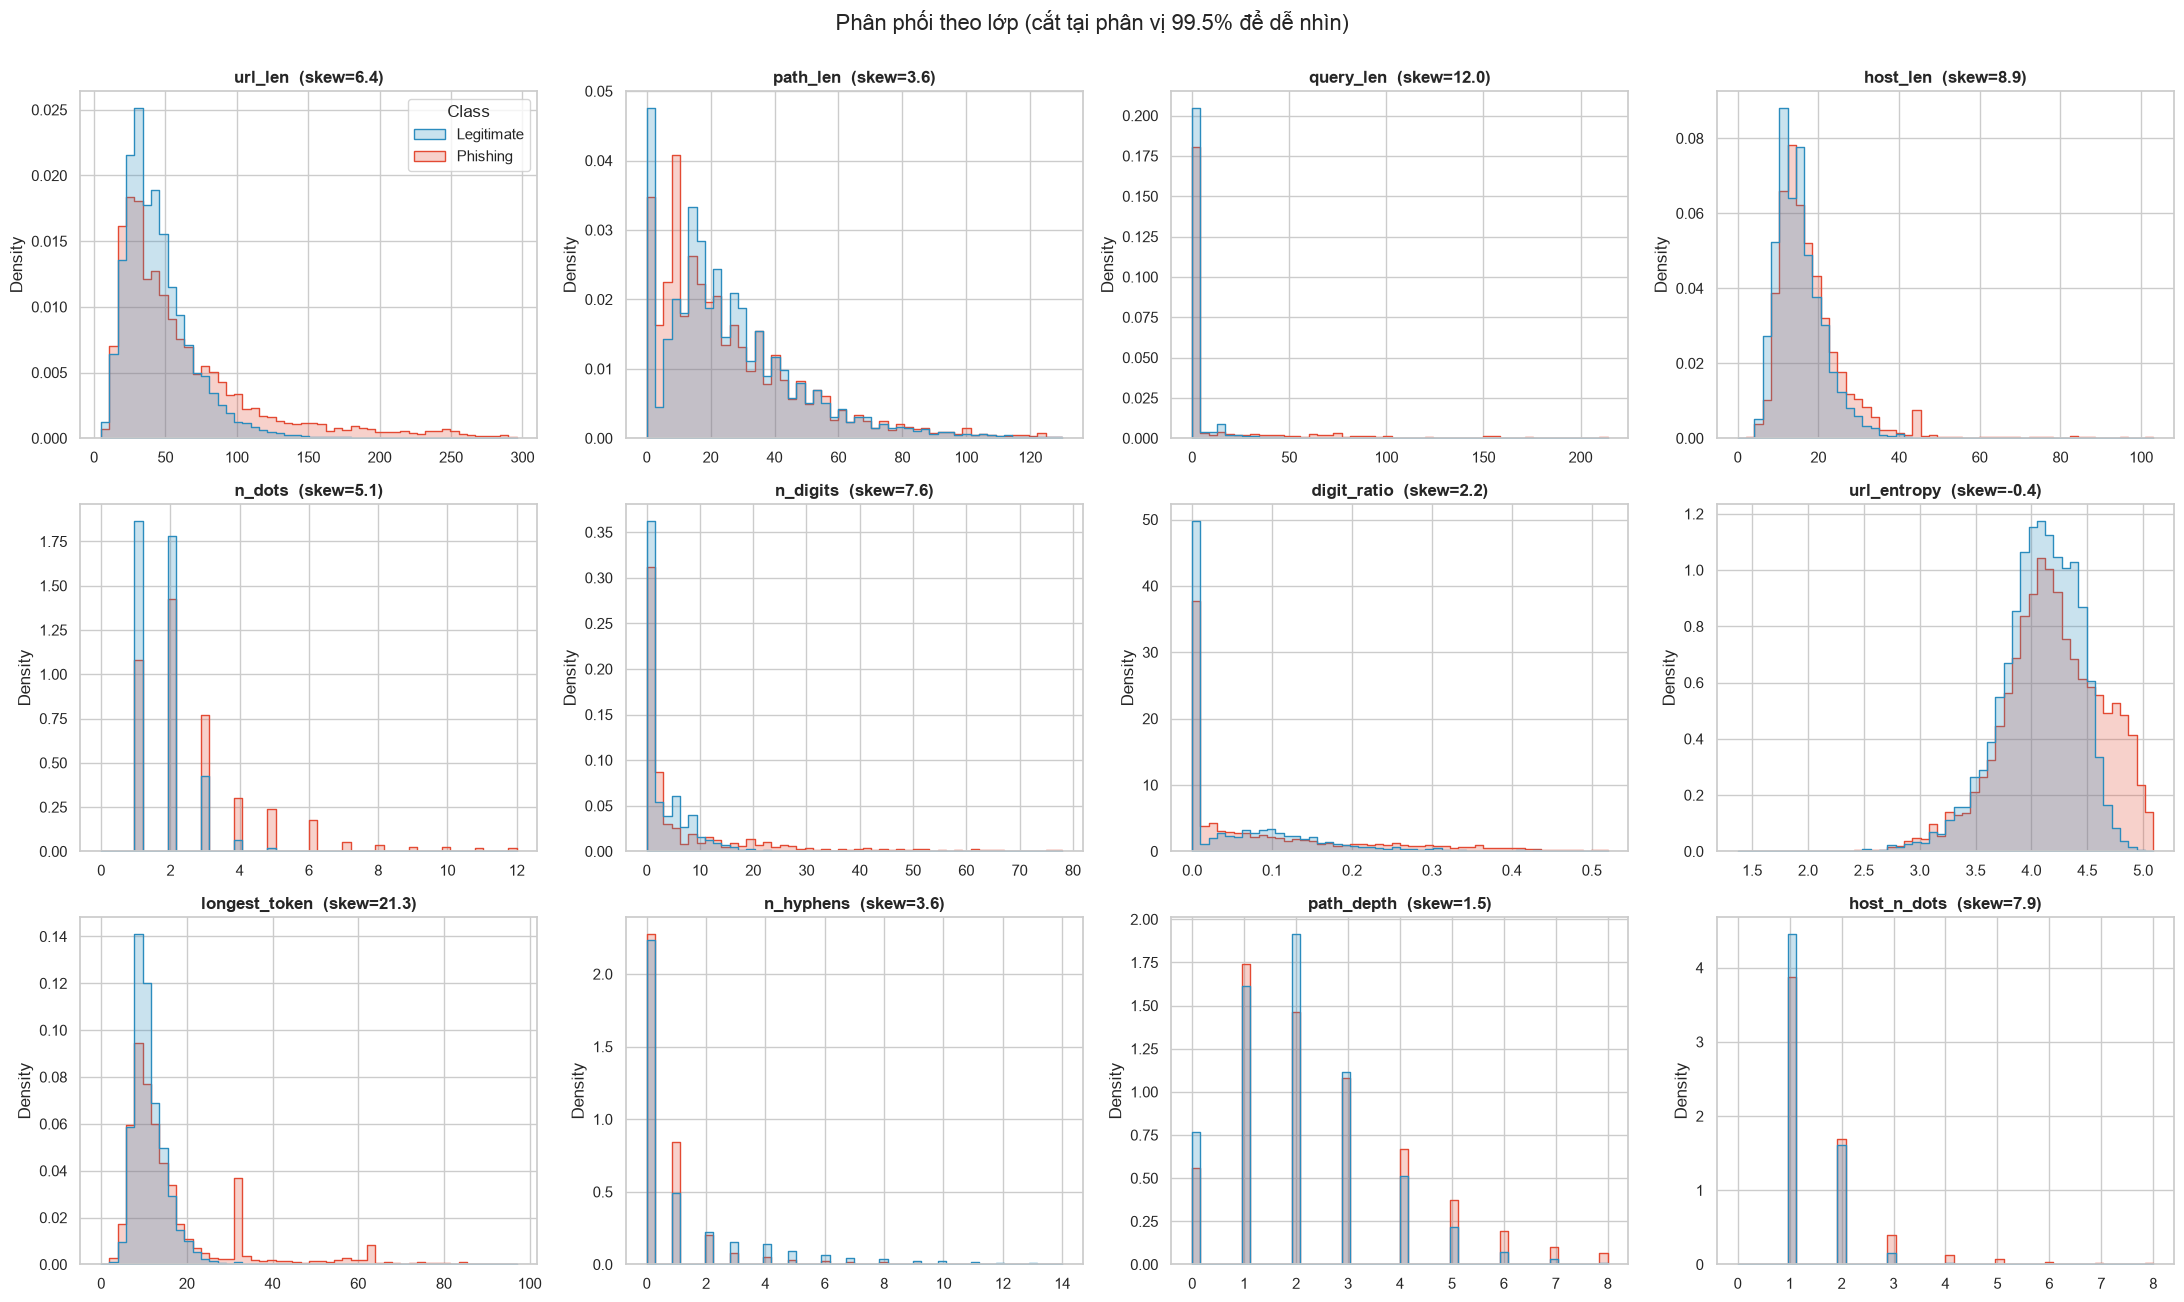

In [9]:
PLOT_COLS = ['url_len', 'path_len', 'query_len', 'host_len', 'n_dots', 'n_digits',
             'digit_ratio', 'url_entropy', 'longest_token', 'n_hyphens', 'path_depth', 'host_n_dots']
viz = D[PLOT_COLS].assign(Class=np.where(y == 1, 'Phishing', 'Legitimate')).sample(150_000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(3, 4, figsize=(22, 13))
for ax, col in zip(axes.ravel(), PLOT_COLS):
    data = viz[viz[col] <= viz[col].quantile(0.995)]
    sns.histplot(data=data, x=col, hue='Class', stat='density', common_norm=False, element='step',
                 bins=50, palette=PALETTE, ax=ax, legend=(col == PLOT_COLS[0]))
    ax.set_title(f'{col}  (skew={prof.loc[col, "Skewness"]:.1f})', fontweight='bold')
    ax.set_xlabel('')
fig.suptitle('Phân phối theo lớp (cắt tại phân vị 99.5% để dễ nhìn)', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

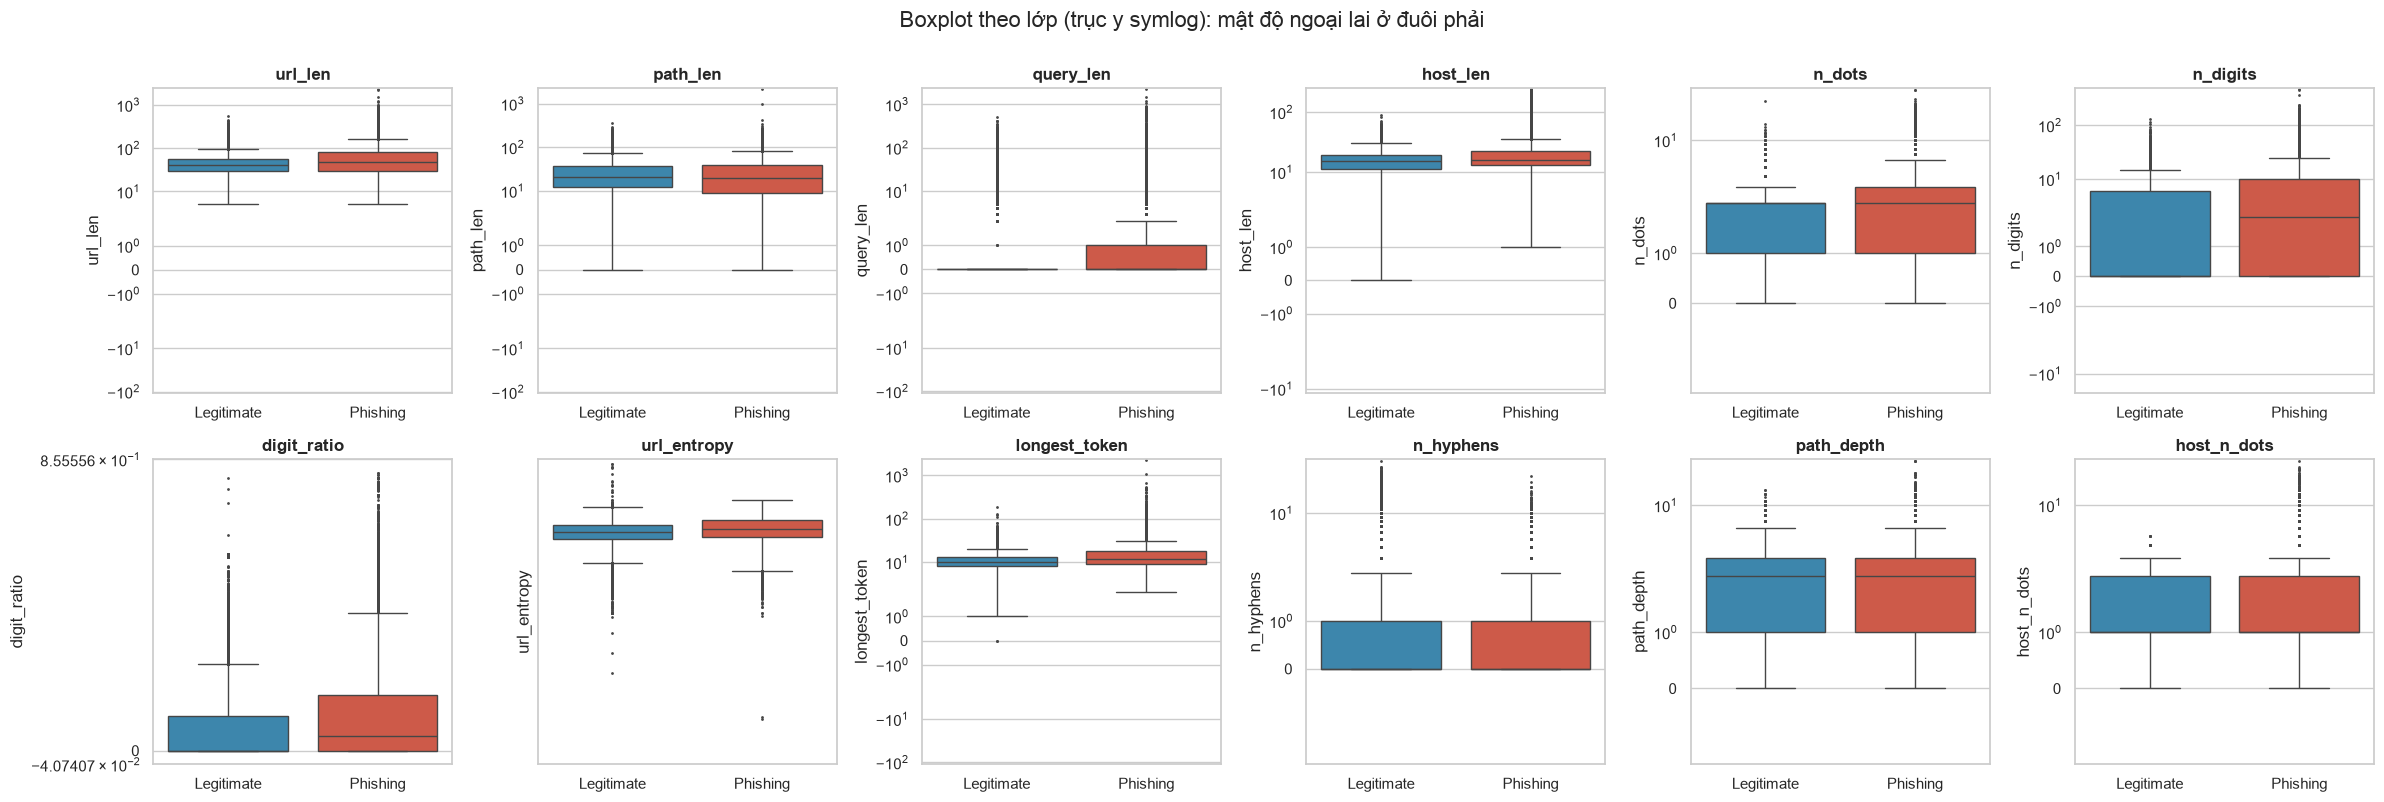

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for ax, col in zip(axes.ravel(), PLOT_COLS):
    sns.boxplot(data=viz, x='Class', y=col, hue='Class', palette=PALETTE, ax=ax, fliersize=1, legend=False)
    ax.set_yscale('symlog')
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('')
fig.suptitle('Boxplot theo lớp (trục y symlog): mật độ ngoại lai ở đuôi phải', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

**Nhận xét: profiling và phân phối**

1. **Lệch phải và đuôi dày gần như ở mọi biến:** 13/14 bộ mô tả có |skew| > 1 và 13/14 có kurtosis > 3. Nặng nhất là `longest_token` (skew 21.3, kurtosis 1,865), `query_len` (skew 12.0, kurtosis 279) và `host_len` (skew 8.9). Chỉ `url_entropy` gần đối xứng (skew −0.39).
2. **Thang đo chênh lệch tới 5 bậc độ lớn:** Variance của `url_len` là 1,852, còn của `digit_ratio` là 0.011. Mô hình dựa trên khoảng cách hoặc gradient (LR, SVM, k-NN, MLP) sẽ bị biến có thang lớn chi phối nếu không chuẩn hóa.
3. **IQR = 0 ở biến thưa:** `query_len` có median = 0 và IQR = 0, nên **mọi** URL có query đều bị quy tắc Tukey coi là ngoại lai (15.3%). Đây là lý do `IQRClipper` ở Phase 2 cần chốt an toàn cho trường hợp IQR = 0.
4. **Ngoại lai chính là tín hiệu:** boxplot cho thấy đuôi phải dày đặc hơn hẳn ở lớp Phishing. Ví dụ điển hình là `longest_token`: **7.15% URL phishing có token dài nhất đúng 32 ký tự**, tức độ dài của mã băm **MD5** mà phishing kit dùng để sinh thư mục ngẫu nhiên. Tỉ lệ này ở URL hợp lệ chỉ là 0.18%, **chênh 40 lần**. Xóa ngoại lai là xóa tín hiệu.
5. **Khác biệt có ý nghĩa thống kê nhưng nhỏ về độ lớn:** mọi Mann–Whitney p ≈ 0 (do n = 500k), nhưng Cliff's δ chỉ ở mức "vừa" với `n_dots` (0.344). Các biến khác ở mức "nhỏ" hoặc "không đáng kể", và **AUC đơn biến tốt nhất chỉ 0.672**. Hai phân phối **chồng lấn mạnh**, nên không có biến đơn lẻ nào đủ để phân loại.
6. `path_len` có median gần như bằng nhau giữa hai lớp (21 so với 20, δ = −0.025), nhưng mục 5.1 sẽ cho thấy biến này **không vô dụng**: quan hệ của nó với nhãn là **phi đơn điệu**, nên các thống kê vị trí như median không nhìn thấy được.

## 4. Các thách thức cốt lõi của bộ dữ liệu

Bảng dưới tổng hợp các thách thức, mỗi thách thức kèm **bằng chứng định lượng** tính từ dữ liệu và **hệ quả** cho các phase sau.

In [11]:
skewed = prof.index[prof['Skewness'].abs() > 1].tolist()
heavy = prof.index[prof['Kurtosis'] > 3].tolist()
dup_vec = D.duplicated(keep=False)
amb = D.assign(y=y).groupby(DESC_COLS)['y'].transform('nunique') > 1
challenges = pd.DataFrame([
    ['Mất cân bằng lớp', f'{imbalance_ratio:.2f} : 1 (phishing {y.mean():.1%})',
     'Accuracy gây hiểu lầm (luôn đoán "hợp lệ" đã đạt ~78%). Cần PR-AUC/F1, class weight và chọn ngưỡng'],
    ['Phân phối lệch, đuôi dày', f'{len(skewed)}/{len(DESC_COLS)} biến |skew|>1; {len(heavy)} biến kurtosis>3',
     'Mô hình tuyến tính/MLP nhạy với thang đo nên cần Winsorizing + Yeo-Johnson + scaling (Phase 2)'],
    ['Ngoại lai hợp lệ về ngữ nghĩa', f'Tối đa {prof["% ngoại lai (Tukey 1.5)"].max():.1f}% ngoại lai/biến; '
     f'url_len max = {int(prof.loc["url_len", "Max"]):,}',
     'Ngoại lai thường chính là phishing (URL nhồi tham số), nên chỉ cắt mềm và giữ bản gốc cho mô hình cây'],
    ['Chồng lấn phân phối', f'AUC đơn biến tốt nhất = {class_diff["AUC đơn biến"].max():.3f}',
     'Không có "đặc trưng vàng" nên phải kết hợp nhiều tín hiệu yếu'],
    ['Vector mô tả mơ hồ', f'{amb.mean():.1%} URL có vector 14 chiều trùng với URL khác nhãn',
     'Cần biểu diễn giàu thông tin hơn (TF-IDF n-gram, đặc trưng bảo mật) ở Phase 3'],
    ['Phân cụm theo domain', f'{df["registered_domain"].nunique():,} domain; {dom_pure:.1%} domain chỉ có 1 nhãn',
     'Chia ngẫu nhiên sẽ rò rỉ domain, nên phải chia theo nhóm domain (Phase 2)'],
    ['Thiên lệch định dạng', f'URL thô không có "/": P(phish) = {shortcut.iloc[0, 2]:.3f}',
     'Bắt buộc chuẩn hóa URL dùng chung cho train và inference'],
    ['Biến phân loại lực lượng lớn', f'{df["tld"].nunique():,} TLD khác nhau',
     'One-hot quá thưa, nên dùng Target Encoding cross-fitted hoặc CatBoost native categorical'],
], columns=['Thách thức', 'Bằng chứng định lượng', 'Hệ quả cho pipeline'])
display(challenges)

,Thách thức,Bằng chứng định lượng,Hệ quả cho pipeline
0,Mất cân bằng lớp,3.61 : 1 (phishing 21.7%),"Accuracy gây hiểu lầm (luôn đoán ""hợp lệ"" đã đ..."
1,"Phân phối lệch, đuôi dày",13/14 biến |skew|>1; 13 biến kurtosis>3,Mô hình tuyến tính/MLP nhạy với thang đo nên c...
2,Ngoại lai hợp lệ về ngữ nghĩa,"Tối đa 15.6% ngoại lai/biến; url_len max = 2,307",Ngoại lai thường chính là phishing (URL nhồi t...
3,Chồng lấn phân phối,AUC đơn biến tốt nhất = 0.672,"Không có ""đặc trưng vàng"" nên phải kết hợp nhi..."
4,Vector mô tả mơ hồ,8.7% URL có vector 14 chiều trùng với URL khác...,Cần biểu diễn giàu thông tin hơn (TF-IDF n-gra...
5,Phân cụm theo domain,"151,535 domain; 99.8% domain chỉ có 1 nhãn","Chia ngẫu nhiên sẽ rò rỉ domain, nên phải chia..."
6,Thiên lệch định dạng,"URL thô không có ""/"": P(phish) = 0.986",Bắt buộc chuẩn hóa URL dùng chung cho train và...
7,Biến phân loại lực lượng lớn,810 TLD khác nhau,"One-hot quá thưa, nên dùng Target Encoding cro..."


## 5. Chứng minh tính phi tuyến (Non-linearity Proof)

**Giả thuyết H₀ (tuyến tính):** log-odds của P(phishing | x) là một **hàm tuyến tính** của các bộ mô tả (sau biến đổi log), tức là một siêu phẳng đủ để tách hai lớp.

Ta bác bỏ H₀ bằng **năm bằng chứng độc lập**, đi từ đơn biến tới đa biến, từ kiểm định thống kê tới trực quan:

| # | Bằng chứng | Câu hỏi kiểm tra |
|:-:|---|---|
| 5.1 | Quan hệ biên **không đơn điệu** | P(phishing) theo từng bin của một biến có tăng/giảm đều không? |
| 5.2 | **Likelihood-Ratio Test** | Thêm số hạng bậc 2 và tương tác vào logistic có cải thiện có ý nghĩa thống kê không? |
| 5.3 | **Tuyến tính vs. phi tuyến** (CV theo domain) | Cùng đầu vào, mô hình phi tuyến có vượt mô hình tuyến tính một cách nhất quán không? |
| 5.4 | **PCA / t-SNE 2D** | Hai lớp có tách bằng một đường thẳng trong không gian chiếu không? |
| 5.5 | **Biên quyết định 2D** | Biên tối ưu trên mặt phẳng hai biến là đường thẳng hay đường cong? |

In [12]:
# Mẫu con phân tầng dùng chung cho các kiểm định 5.2–5.5
sample_idx, _ = train_test_split(np.arange(len(df)), train_size=SAMPLE_N, stratify=y, random_state=RANDOM_STATE)
Xs = np.log1p(D.iloc[sample_idx][DESC_COLS].to_numpy(dtype=float))   # log1p: giảm lệch trước khi so sánh
ys = y[sample_idx]
gs = df['registered_domain'].to_numpy()[sample_idx]
print(f'Mẫu kiểm định: {len(ys):,} URL, tỉ lệ phishing {ys.mean():.3f}, {len(set(gs)):,} domain')

Mẫu kiểm định: 60,000 URL, tỉ lệ phishing 0.217, 28,613 domain


### 5.1. Quan hệ biên không đơn điệu

Nếu log-odds tuyến tính theo x thì P(phishing) theo các **bin phân vị** của x phải **đơn điệu**. Ta đo mức đơn điệu bằng |Spearman ρ| giữa thứ tự bin và tỉ lệ phishing. Giá trị ρ ≈ ±1 nghĩa là đơn điệu hoàn toàn, |ρ| thấp nghĩa là có dạng chữ U, chữ ∩ hoặc nhiều đỉnh.

,Số bin,"|Spearman ρ| (bin, rate)",Số lần đổi chiều,Min rate,Max rate,Kết luận
Biến,,,,,,
n_digits,11,0.0182,2,0.0755,0.8132,KHÔNG đơn điệu
url_entropy,20,0.0271,9,0.1511,0.7466,KHÔNG đơn điệu
path_len,18,0.1414,10,0.1597,0.4678,KHÔNG đơn điệu
digit_ratio,11,0.2545,2,0.1560,0.5672,KHÔNG đơn điệu
url_len,20,0.2617,6,0.1240,0.6822,KHÔNG đơn điệu
longest_token,14,0.5385,7,0.1431,0.8590,KHÔNG đơn điệu
n_special,13,0.6264,6,0.0880,0.6044,KHÔNG đơn điệu
host_len,16,0.7706,10,0.1058,0.5029,KHÔNG đơn điệu
query_len,4,0.8000,1,0.1067,0.6951,KHÔNG đơn điệu


10/14 biến có quan hệ biên KHÔNG đơn điệu với nhãn.


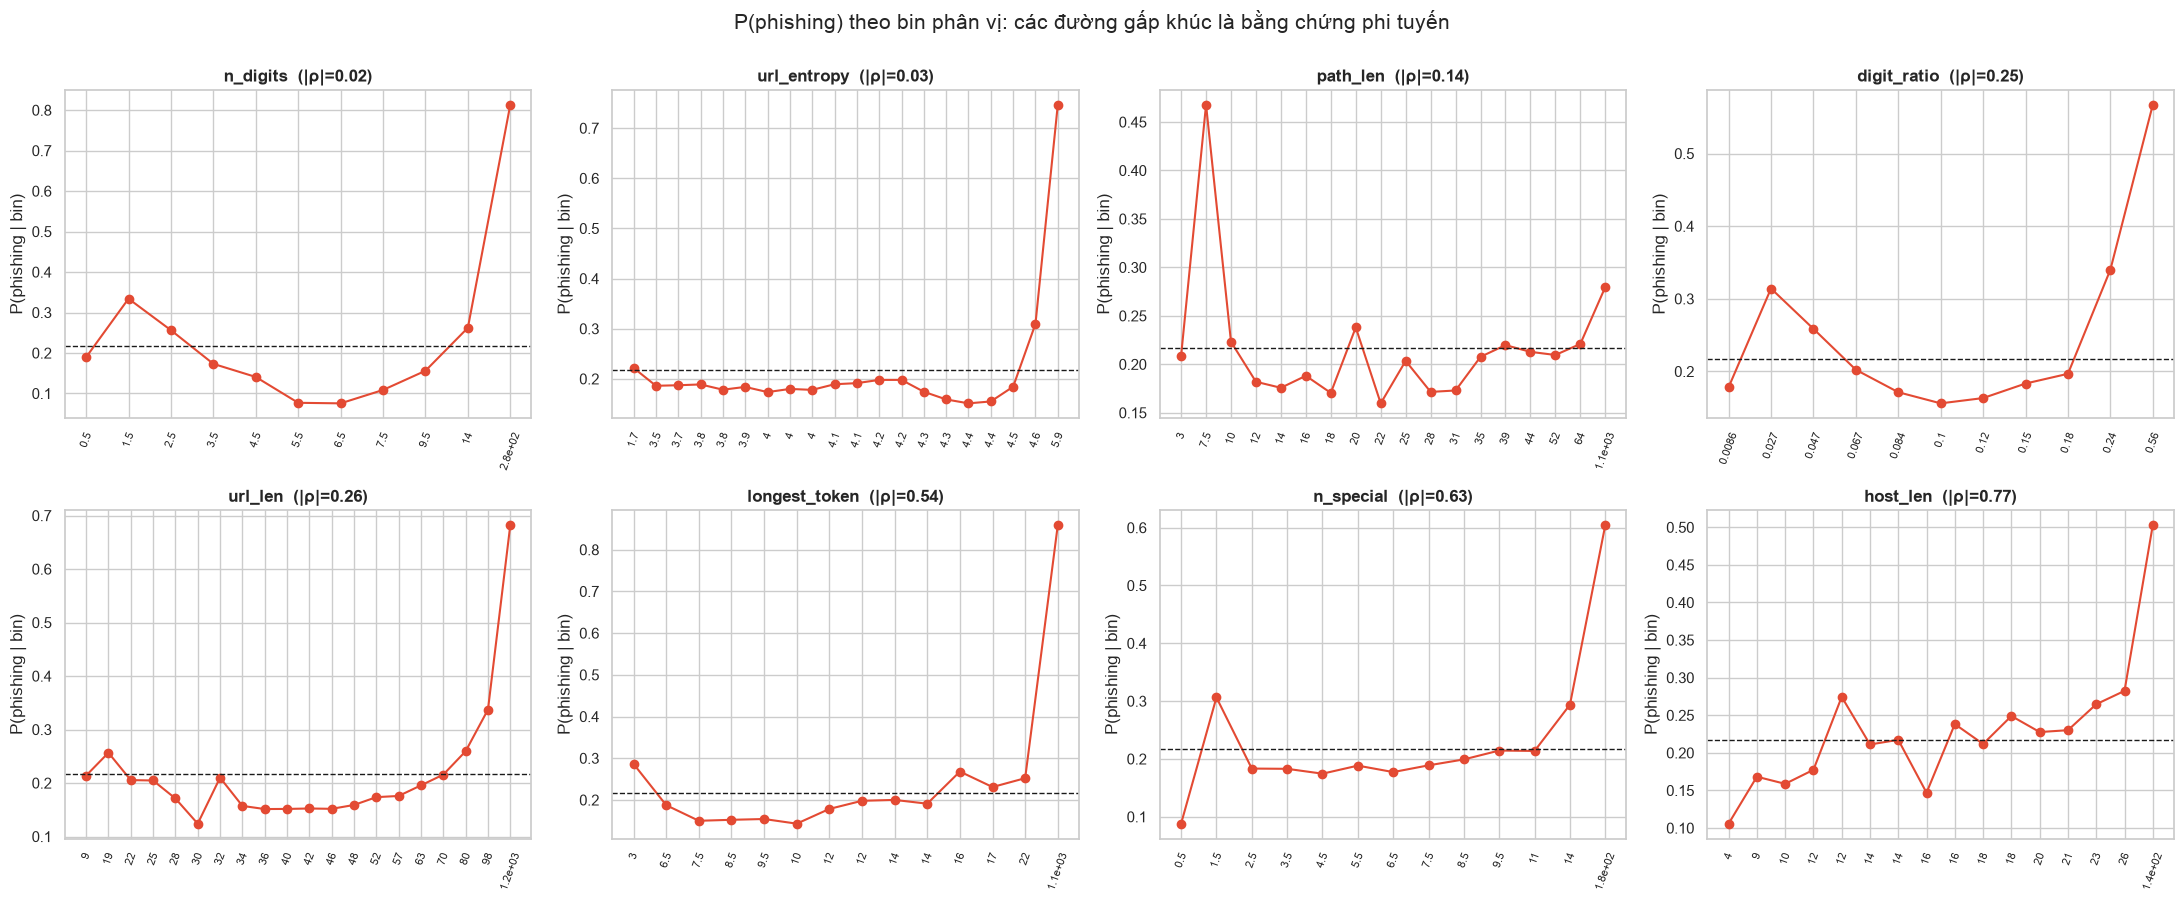

In [13]:
def binned_rate(x, target, q=20):
    bins = pd.qcut(x, q=q, duplicates='drop')
    g = pd.DataFrame({'bin': bins, 'y': target}).groupby('bin', observed=True)['y'].agg(['mean', 'size'])
    g['center'] = [iv.mid for iv in g.index]
    return g


mono_rows, curves = [], {}
for c in DESC_COLS:
    g = binned_rate(D[c], y)
    curves[c] = g
    rho = stats.spearmanr(np.arange(len(g)), g['mean']).statistic if len(g) > 2 else np.nan
    direction_changes = int((np.diff(np.sign(np.diff(g['mean'].to_numpy()))) != 0).sum())
    mono_rows.append({'Biến': c, 'Số bin': len(g), '|Spearman ρ| (bin, rate)': abs(rho),
                      'Số lần đổi chiều': direction_changes,
                      'Min rate': g['mean'].min(), 'Max rate': g['mean'].max(),
                      'Kết luận': 'Đơn điệu' if abs(rho) >= 0.9 else 'KHÔNG đơn điệu'})
mono = pd.DataFrame(mono_rows).set_index('Biến').sort_values('|Spearman ρ| (bin, rate)')
display(mono)
print(f'{(mono["Kết luận"] == "KHÔNG đơn điệu").sum()}/{len(mono)} biến có quan hệ biên KHÔNG đơn điệu với nhãn.')

show = mono.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, c in zip(axes.ravel(), show):
    g = curves[c]
    ax.plot(range(len(g)), g['mean'], marker='o', c='#e34a33')
    ax.axhline(y.mean(), ls='--', c='k', lw=1)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([f'{v:.2g}' for v in g['center']], rotation=70, fontsize=8)
    ax.set_title(f'{c}  (|ρ|={mono.loc[c, "|Spearman ρ| (bin, rate)"]:.2f})', fontweight='bold')
    ax.set_ylabel('P(phishing | bin)')
fig.suptitle('P(phishing) theo bin phân vị: các đường gấp khúc là bằng chứng phi tuyến', fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

### 5.2. Likelihood-Ratio Test: logistic tuyến tính vs. logistic bậc 2

- **Mô hình hạn chế M₀:** logit(p) = β₀ + Σ βᵢxᵢ (14 tham số + hệ số chặn).
- **Mô hình đầy đủ M₁:** thêm mọi số hạng xᵢ² và xᵢxⱼ (bậc 2, 105 tham số mới).
- **Thống kê LR = 2·(ℓ₁ − ℓ₀) ~ χ²(df = 105)** dưới H₀. Nếu p-value ≪ 0.05 thì bác bỏ giả thuyết tuyến tính.

Để chắc chắn cải thiện **không đến từ overfit**, ta fit trên một nửa mẫu và báo cáo thêm log-loss/AUC trên **nửa còn lại** (held-out).

In [14]:
A_idx, B_idx = train_test_split(np.arange(len(ys)), test_size=0.5, stratify=ys, random_state=RANDOM_STATE)
lin = make_pipeline(StandardScaler())
poly = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), StandardScaler())
XA_lin, XB_lin = lin.fit_transform(Xs[A_idx]), lin.transform(Xs[B_idx])
XA_poly, XB_poly = poly.fit_transform(Xs[A_idx]), poly.transform(Xs[B_idx])

# C rất lớn ≈ ước lượng hợp lý cực đại (MLE) không phạt
m0 = LogisticRegression(C=1e6, max_iter=5000).fit(XA_lin, ys[A_idx])
m1 = LogisticRegression(C=1e6, max_iter=5000).fit(XA_poly, ys[A_idx])
ll0 = -log_loss(ys[A_idx], m0.predict_proba(XA_lin)[:, 1], normalize=False)
ll1 = -log_loss(ys[A_idx], m1.predict_proba(XA_poly)[:, 1], normalize=False)
lr_stat = 2 * (ll1 - ll0)
df_lr = XA_poly.shape[1] - XA_lin.shape[1]
p_lr = stats.chi2.sf(lr_stat, df_lr)

lrt = pd.DataFrame({
    'Số tham số': [XA_lin.shape[1] + 1, XA_poly.shape[1] + 1],
    'Log-likelihood (fit)': [ll0, ll1],
    'Log-loss held-out': [log_loss(ys[B_idx], m0.predict_proba(XB_lin)[:, 1]),
                          log_loss(ys[B_idx], m1.predict_proba(XB_poly)[:, 1])],
    'ROC-AUC held-out': [roc_auc_score(ys[B_idx], m0.predict_proba(XB_lin)[:, 1]),
                         roc_auc_score(ys[B_idx], m1.predict_proba(XB_poly)[:, 1])],
    'PR-AUC held-out': [average_precision_score(ys[B_idx], m0.predict_proba(XB_lin)[:, 1]),
                        average_precision_score(ys[B_idx], m1.predict_proba(XB_poly)[:, 1])],
}, index=['M₀: tuyến tính', 'M₁: bậc 2 + tương tác'])
display(lrt)
print(f'LR statistic = {lr_stat:,.1f} | df = {df_lr} | p-value = {p_lr:.3e} | '
      f'giá trị tới hạn χ²(0.999) = {stats.chi2.ppf(0.999, df_lr):.1f}')
print('→ BÁC BỎ H₀ (tuyến tính)' if p_lr < 1e-3 else '→ Không đủ bằng chứng bác bỏ H₀')

,Số tham số,Log-likelihood (fit),Log-loss held-out,ROC-AUC held-out,PR-AUC held-out
M₀: tuyến tính,15,"-11,996.1826",0.3987,0.7967,0.6264
M₁: bậc 2 + tương tác,120,"-8,947.2543",0.3099,0.8982,0.7820


LR statistic = 6,097.9 | df = 105 | p-value = 0.000e+00 | giá trị tới hạn χ²(0.999) = 155.5
→ BÁC BỎ H₀ (tuyến tính)


### 5.3. Cùng đầu vào: mô hình tuyến tính vs. mô hình phi tuyến

So sánh 2 mô hình tuyến tính (Logistic Regression, Linear SVM) với 4 mô hình phi tuyến (Decision Tree, k-NN, Random Forest, Histogram GBDT) trên **cùng 14 bộ mô tả**. Ta dùng **5-fold StratifiedGroupKFold theo domain** để không fold nào chia sẻ domain. Kiểm định **t-test ghép cặp** trên 5 fold xác nhận chênh lệch không phải do ngẫu nhiên.

,Họ,ROC-AUC,PR-AUC,F1@0.5,PR-AUC (mean),Thời gian (s)
Mô hình,,,,,,
Logistic Regression,Tuyến tính,0.7899 ± 0.0178,0.6212 ± 0.0324,0.4887 ± 0.0198,0.6212,3.0457
Linear SVM,Tuyến tính,0.7857 ± 0.0189,0.6224 ± 0.0334,0.4639 ± 0.0183,0.6224,3.0020
Decision Tree (depth 12),Phi tuyến,0.8541 ± 0.0202,0.6951 ± 0.0274,0.6202 ± 0.0123,0.6951,3.4440
k-NN (k=31),Phi tuyến,0.8833 ± 0.0147,0.7473 ± 0.0371,0.6343 ± 0.0296,0.7473,7.4194
Random Forest,Phi tuyến,0.8992 ± 0.0110,0.7932 ± 0.0172,0.6848 ± 0.0205,0.7932,15.2331
Hist Gradient Boosting,Phi tuyến,0.9016 ± 0.0128,0.7871 ± 0.0252,0.6788 ± 0.0182,0.7871,9.4695


Paired t-test PR-AUC: Random Forest vs Linear SVM: Δ = +0.1708, t = 9.27, p = 7.52e-04


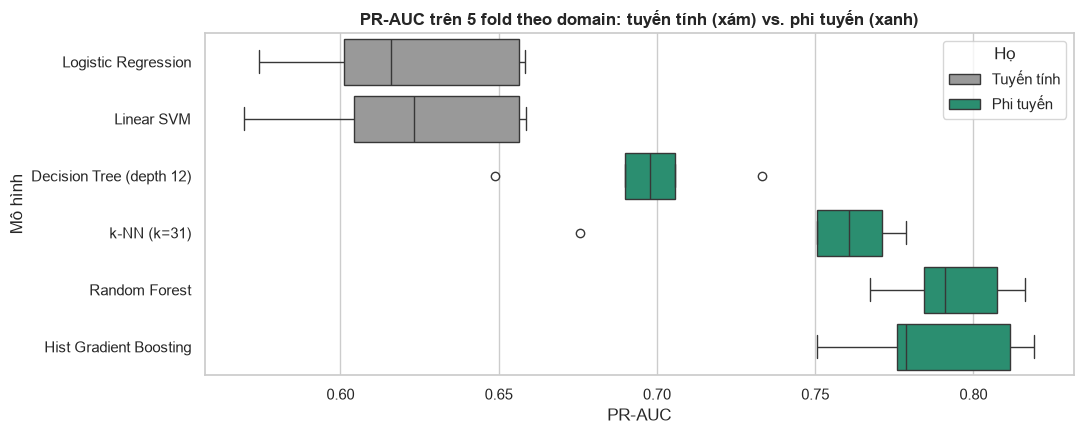

In [15]:
log_scaler = [FunctionTransformer(np.log1p), StandardScaler()]
Xs_raw = D.iloc[sample_idx][DESC_COLS].to_numpy(dtype=float)
cv_models = {
    'Logistic Regression': ('Tuyến tính', make_pipeline(*log_scaler, LogisticRegression(max_iter=2000))),
    'Linear SVM': ('Tuyến tính', make_pipeline(*log_scaler, LinearSVC(C=1.0))),
    'Decision Tree (depth 12)': ('Phi tuyến', DecisionTreeClassifier(max_depth=12, min_samples_leaf=20,
                                                                    random_state=RANDOM_STATE)),
    'k-NN (k=31)': ('Phi tuyến', make_pipeline(*log_scaler, KNeighborsClassifier(n_neighbors=31, n_jobs=-1))),
    'Random Forest': ('Phi tuyến', RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1,
                                                          random_state=RANDOM_STATE)),
    'Hist Gradient Boosting': ('Phi tuyến', HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
}
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores, cv_rows = {}, []
for name, (family, model) in cv_models.items():
    t0 = time.time()
    r = cross_validate(model, Xs_raw, ys, groups=gs, cv=sgkf, scoring=['roc_auc', 'average_precision', 'f1'])
    cv_scores[name] = r
    cv_rows.append({'Mô hình': name, 'Họ': family,
                    'ROC-AUC': f"{r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.4f}",
                    'PR-AUC': f"{r['test_average_precision'].mean():.4f} ± {r['test_average_precision'].std():.4f}",
                    'F1@0.5': f"{r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f}",
                    'PR-AUC (mean)': r['test_average_precision'].mean(), 'Thời gian (s)': time.time() - t0})
cv_tbl = pd.DataFrame(cv_rows).set_index('Mô hình')
display(cv_tbl)

best_lin = cv_tbl[cv_tbl['Họ'] == 'Tuyến tính']['PR-AUC (mean)'].idxmax()
best_nl = cv_tbl[cv_tbl['Họ'] == 'Phi tuyến']['PR-AUC (mean)'].idxmax()
a, b = cv_scores[best_nl]['test_average_precision'], cv_scores[best_lin]['test_average_precision']
t_stat, p_t = stats.ttest_rel(a, b)
print(f'Paired t-test PR-AUC: {best_nl} vs {best_lin}: Δ = {np.mean(a - b):+.4f}, t = {t_stat:.2f}, p = {p_t:.2e}')

fig, ax = plt.subplots(figsize=(11, 4.5))
plot_df = pd.DataFrame({n: cv_scores[n]['test_average_precision'] for n in cv_models}).melt(var_name='Mô hình',
                                                                                             value_name='PR-AUC')
plot_df['Họ'] = plot_df['Mô hình'].map({n: f for n, (f, _) in cv_models.items()})
sns.boxplot(data=plot_df, y='Mô hình', x='PR-AUC', hue='Họ', palette={'Tuyến tính': '#999999', 'Phi tuyến': '#1b9e77'},
            ax=ax)
ax.set_title('PR-AUC trên 5 fold theo domain: tuyến tính (xám) vs. phi tuyến (xanh)', fontweight='bold')
plt.tight_layout()
plt.show()

### 5.4. Trực quan hóa giảm chiều: PCA (tuyến tính) và t-SNE (phi tuyến)

- **PCA** chiếu dữ liệu lên 2 hướng có phương sai lớn nhất. Đây là phép chiếu **tuyến tính**: nếu hai lớp tách được bằng siêu phẳng thì thường cũng tách khá rõ ở đây.
- **t-SNE** bảo toàn **lân cận cục bộ** (phi tuyến). Nếu phishing tạo thành **nhiều cụm nhỏ rời rạc** xen giữa vùng hợp lệ, thì đó là dấu hiệu của đa tạp phi tuyến: một siêu phẳng không thể bao trọn các "ốc đảo" này.

Ta định lượng thêm: một **Logistic Regression** và một **HistGBDT** được fit trên đúng 2 thành phần PCA, nhằm đo xem mô hình phi tuyến khai thác 2D tốt hơn bao nhiêu.

PCA: PC1+PC2 giải thích 59.4% phương sai; cần 6 thành phần để đạt 90%
ROC-AUC trên 2D-PCA: Logistic = 0.6590 | HistGBDT = 0.7324


t-SNE 6,000 điểm: 19.4s


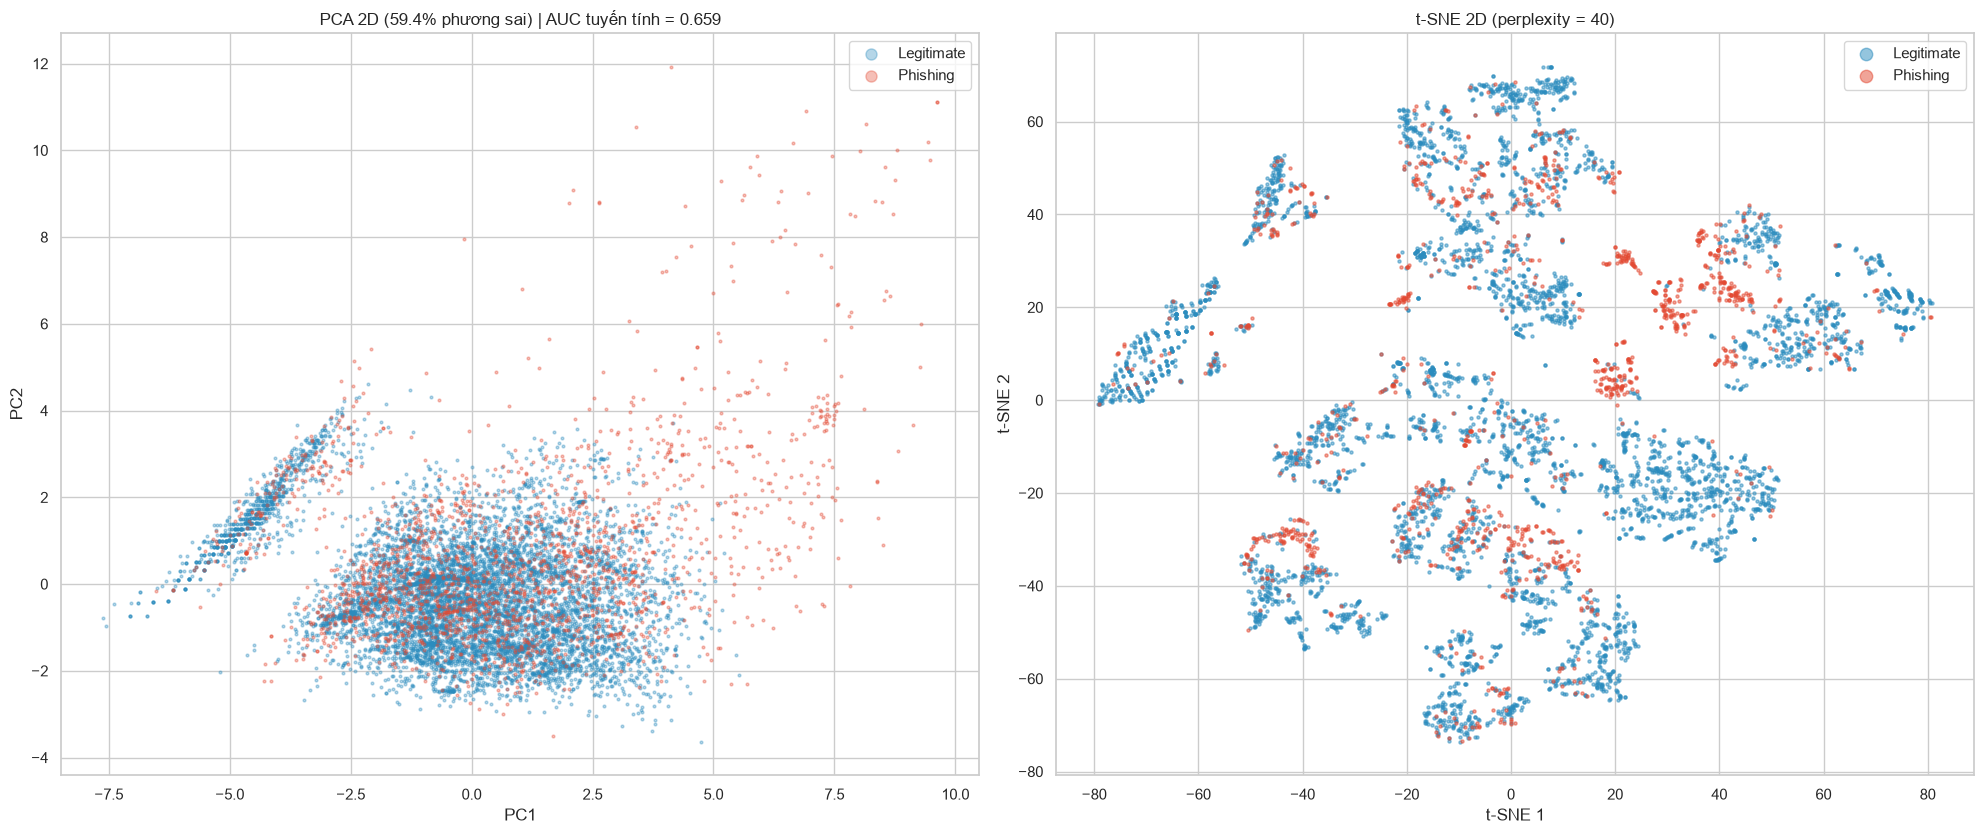

,PC1,PC2
url_len,0.3857,0.0667
n_special,0.3782,-0.0224
url_entropy,0.3596,0.0225
path_len,0.3230,-0.2963
n_slashes,0.3224,-0.2825
path_depth,0.3098,-0.3095


In [16]:
Z = StandardScaler().fit_transform(Xs)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z)
P2 = pca.transform(Z)
pca_full = PCA(random_state=RANDOM_STATE).fit(Z)
k90 = int(np.searchsorted(np.cumsum(pca_full.explained_variance_ratio_), 0.90) + 1)

P_tr, P_te, yp_tr, yp_te = train_test_split(P2, ys, test_size=0.3, stratify=ys, random_state=RANDOM_STATE)
auc_pca_lin = roc_auc_score(yp_te, LogisticRegression().fit(P_tr, yp_tr).predict_proba(P_te)[:, 1])
auc_pca_nl = roc_auc_score(yp_te, HistGradientBoostingClassifier(random_state=RANDOM_STATE)
                           .fit(P_tr, yp_tr).predict_proba(P_te)[:, 1])
print(f'PCA: PC1+PC2 giải thích {pca.explained_variance_ratio_.sum():.1%} phương sai; cần {k90} thành phần để đạt 90%')
print(f'ROC-AUC trên 2D-PCA: Logistic = {auc_pca_lin:.4f} | HistGBDT = {auc_pca_nl:.4f}')

t0 = time.time()
ts_idx = np.random.RandomState(RANDOM_STATE).choice(len(Z), TSNE_N, replace=False)
T2 = TSNE(n_components=2, perplexity=40, init='pca', learning_rate='auto',
          random_state=RANDOM_STATE).fit_transform(Z[ts_idx])
print(f't-SNE {TSNE_N:,} điểm: {time.time() - t0:.1f}s')

fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))
vis = np.random.RandomState(1).choice(len(P2), 10_000, replace=False)
for cls, name in [(0, 'Legitimate'), (1, 'Phishing')]:
    m = ys[vis] == cls
    axes[0].scatter(P2[vis][m, 0], P2[vis][m, 1], s=4, alpha=0.35, c=PALETTE[name], label=name)
    m2 = ys[ts_idx] == cls
    axes[1].scatter(T2[m2, 0], T2[m2, 1], s=5, alpha=0.5, c=PALETTE[name], label=name)
axes[0].set(title=f'PCA 2D ({pca.explained_variance_ratio_.sum():.1%} phương sai) | AUC tuyến tính = {auc_pca_lin:.3f}',
            xlabel='PC1', ylabel='PC2')
axes[1].set(title='t-SNE 2D (perplexity = 40)', xlabel='t-SNE 1', ylabel='t-SNE 2')
for ax in axes:
    ax.legend(markerscale=4)
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca.components_.T, index=DESC_COLS, columns=['PC1', 'PC2'])
display(loadings.sort_values('PC1', key=np.abs, ascending=False).head(6))

### 5.5. Biên quyết định trên mặt phẳng hai biến

Chọn hai biến có ý nghĩa bảo mật: **độ dài URL (log)** và **entropy của URL**. Ba mô hình được fit trên cùng hai biến:
- **Logistic Regression**: biên bắt buộc là một **đường thẳng**.
- **Logistic Regression + đa thức bậc 3**: biên là đường cong trơn.
- **HistGBDT**: biên là các vùng hình bậc thang, linh hoạt tùy ý.

Nếu dữ liệu tuyến tính thì ba mô hình phải cho AUC tương đương.

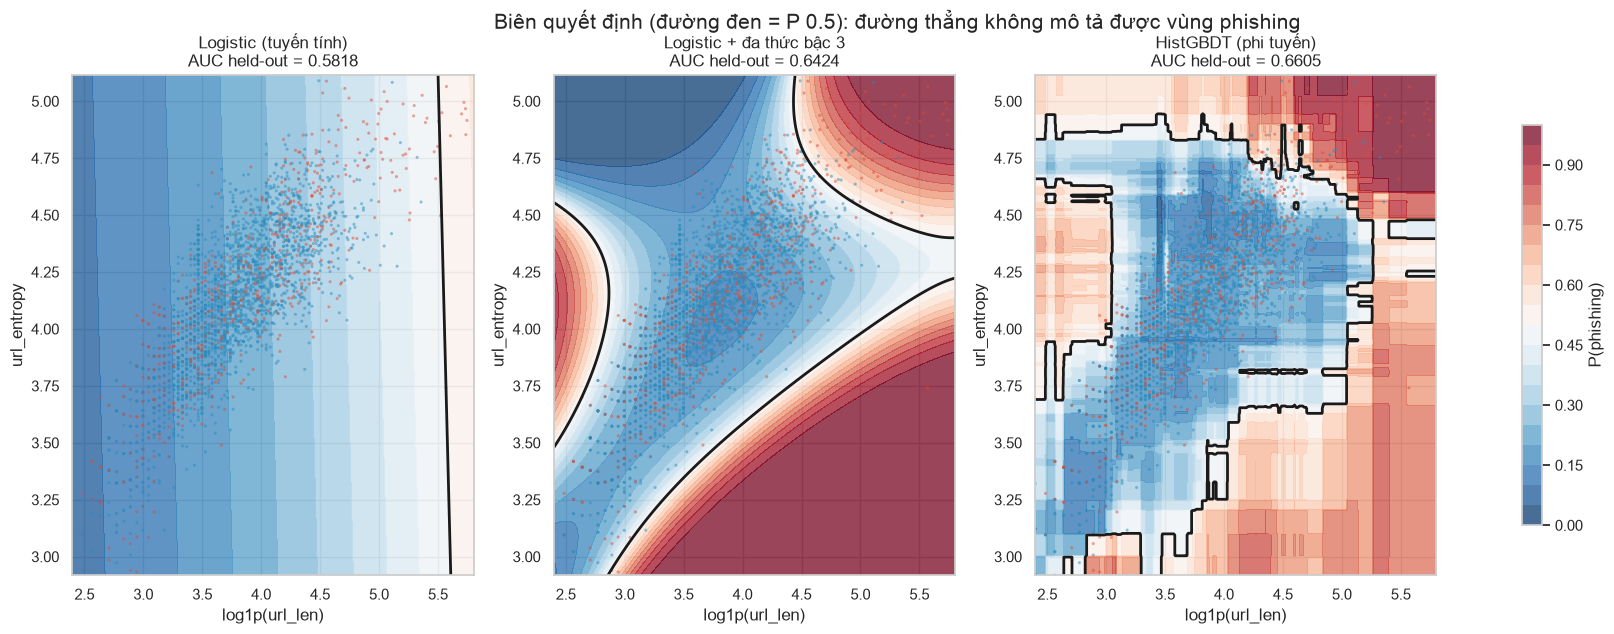

,ROC-AUC held-out
Logistic (tuyến tính),0.5818
Logistic + đa thức bậc 3,0.6424
HistGBDT (phi tuyến),0.6605


In [17]:
f1_name, f2_name = 'url_len', 'url_entropy'
X2 = np.column_stack([np.log1p(D.iloc[sample_idx][f1_name]), D.iloc[sample_idx][f2_name]])
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, ys, test_size=0.3, stratify=ys, random_state=RANDOM_STATE)
boundary_models = {
    'Logistic (tuyến tính)': make_pipeline(StandardScaler(), LogisticRegression()),
    'Logistic + đa thức bậc 3': make_pipeline(StandardScaler(), PolynomialFeatures(3), StandardScaler(),
                                              LogisticRegression(max_iter=3000)),
    'HistGBDT (phi tuyến)': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
x_min, x_max = np.percentile(X2[:, 0], [0.5, 99.5])
y_min, y_max = np.percentile(X2[:, 1], [0.5, 99.5])
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
pts = np.random.RandomState(2).choice(len(X2_te), 3000, replace=False)
boundary_auc = {}
for ax, (name, model) in zip(axes, boundary_models.items()):
    model.fit(X2_tr, y2_tr)
    boundary_auc[name] = roc_auc_score(y2_te, model.predict_proba(X2_te)[:, 1])
    zz = model.predict_proba(grid)[:, 1].reshape(xx.shape)
    cf = ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 21), cmap='RdBu_r', alpha=0.75)
    ax.contour(xx, yy, zz, levels=[0.5], colors='k', linewidths=2)
    ax.scatter(X2_te[pts, 0], X2_te[pts, 1], c=np.where(y2_te[pts] == 1, PALETTE['Phishing'], PALETTE['Legitimate']),
               s=5, alpha=0.5, edgecolors='none')
    ax.set(title=f'{name}\nAUC held-out = {boundary_auc[name]:.4f}', xlabel=f'log1p({f1_name})', ylabel=f2_name,
           xlim=(x_min, x_max), ylim=(y_min, y_max))
fig.colorbar(cf, ax=axes, shrink=0.8, label='P(phishing)')
fig.suptitle('Biên quyết định (đường đen = P 0.5): đường thẳng không mô tả được vùng phishing', fontsize=15)
plt.show()
display(pd.Series(boundary_auc, name='ROC-AUC held-out').to_frame())

### 5.6. Tổng hợp bằng chứng phi tuyến

In [18]:
evidence = pd.DataFrame([
    ['5.1 Quan hệ biên', f'{(mono["Kết luận"] == "KHÔNG đơn điệu").sum()}/{len(mono)} biến không đơn điệu',
     'Hiệu ứng của một biến đổi chiều theo vùng giá trị'],
    ['5.2 Likelihood-Ratio Test', f'LR = {lr_stat:,.0f}, df = {df_lr}, p = {p_lr:.1e}; held-out AUC '
     f'{lrt.iloc[0, 3]:.3f} → {lrt.iloc[1, 3]:.3f}', 'Bác bỏ H₀ tuyến tính, và cải thiện tổng quát hóa được'],
    ['5.3 Tuyến tính vs phi tuyến', f'PR-AUC {cv_tbl.loc[best_lin, "PR-AUC (mean)"]:.3f} ({best_lin}) → '
     f'{cv_tbl.loc[best_nl, "PR-AUC (mean)"]:.3f} ({best_nl}); paired t p = {p_t:.1e}',
     'Mô hình phi tuyến vượt trội nhất quán trên mọi fold'],
    ['5.4 PCA / t-SNE', f'2D-PCA AUC: tuyến tính {auc_pca_lin:.3f} vs GBDT {auc_pca_nl:.3f}',
     'Phishing tạo nhiều cụm rời rạc, không phải một nửa không gian'],
    ['5.5 Biên quyết định 2D', ' | '.join(f'{k.split(" (")[0]}: {v:.3f}' for k, v in boundary_auc.items()),
     'Biên tối ưu là đường cong / nhiều vùng'],
], columns=['Bằng chứng', 'Số liệu', 'Diễn giải'])
display(evidence)

summary = {
    'n_raw': int(n_raw), 'n_canonical': int(len(df)), 'n_domains': int(df['registered_domain'].nunique()),
    'phishing_rate': float(y.mean()), 'imbalance_ratio': float(imbalance_ratio),
    'n_skewed_descriptors': len(skewed), 'ambiguous_vector_rate': float(amb.mean()),
    'lrt': {'statistic': float(lr_stat), 'df': int(df_lr), 'p_value': float(p_lr)},
    'cv_pr_auc': {n: float(cv_scores[n]['test_average_precision'].mean()) for n in cv_models},
    'paired_ttest': {'best_nonlinear': best_nl, 'best_linear': best_lin, 't': float(t_stat), 'p': float(p_t)},
    'pca_2d_auc': {'linear': float(auc_pca_lin), 'gbdt': float(auc_pca_nl)},
    'boundary_auc': {k: float(v) for k, v in boundary_auc.items()},
}
(REPORT_DIR / 'phase1_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print('Đã lưu artifacts/reports/phase1_summary.json, phase1_profile.csv, phase1_class_difference.csv, '
      'phase1_data_dictionary.csv')

,Bằng chứng,Số liệu,Diễn giải
0,5.1 Quan hệ biên,10/14 biến không đơn điệu,Hiệu ứng của một biến đổi chiều theo vùng giá trị
1,5.2 Likelihood-Ratio Test,"LR = 6,098, df = 105, p = 0.0e+00; held-out AU...","Bác bỏ H₀ tuyến tính, và cải thiện tổng quát h..."
2,5.3 Tuyến tính vs phi tuyến,PR-AUC 0.622 (Linear SVM) → 0.793 (Random Fore...,Mô hình phi tuyến vượt trội nhất quán trên mọi...
3,5.4 PCA / t-SNE,2D-PCA AUC: tuyến tính 0.659 vs GBDT 0.732,"Phishing tạo nhiều cụm rời rạc, không phải một..."
4,5.5 Biên quyết định 2D,Logistic: 0.582 | Logistic + đa thức bậc 3: 0....,Biên tối ưu là đường cong / nhiều vùng


Đã lưu artifacts/reports/phase1_summary.json, phase1_profile.csv, phase1_class_difference.csv, phase1_data_dictionary.csv


**Kết luận §5: dữ liệu mang bản chất phi tuyến. H₀ bị bác bỏ bởi cả năm bằng chứng.**

- **5.1:** 10/14 biến có P(phishing) theo bin **không đơn điệu**. Ví dụ `url_entropy` đổi chiều 9 lần và `path_len` đổi chiều 10 lần, với |ρ| chỉ 0.03 và 0.14. Một hệ số tuyến tính duy nhất (một độ dốc) không thể mô tả đường cong lên xuống như vậy.
- **5.2:** LR = 6,098 ≫ giá trị tới hạn χ²₁₀₅(0.999) = 155.5, p < 10⁻³⁰⁰. Quan trọng hơn, cải thiện **tổng quát hóa được** trên nửa held-out: ROC-AUC tăng **0.797 → 0.898**, PR-AUC tăng **0.626 → 0.782**, log-loss giảm **0.399 → 0.310**. Như vậy số hạng bậc 2 và tương tác mô tả cấu trúc thật, không phải nhiễu.
- **5.3:** trên cùng 14 biến, mọi mô hình phi tuyến đều vượt mọi mô hình tuyến tính. PR-AUC tăng từ **0.62 (LR/SVM) lên 0.79 (Random Forest)**, tức **+0.17**, với paired t-test p = 7.5×10⁻⁴ trên 5 fold theo domain. F1@0.5 của mô hình tuyến tính chỉ khoảng 0.47–0.49, khớp với hiện tượng LR underfit ở code cũ (Recall 0.45).
- **5.4:** PCA cần 6 thành phần mới giữ được 90% phương sai, và trên 2D-PCA HistGBDT vẫn hơn Logistic (AUC 0.732 so với 0.659). Trên PCA, phần lớn phishing **chồng khít** lên khối hợp lệ ở tâm, chỉ có một "đuôi" phishing tách ra theo hướng PC1 dương (URL dài, nhiều ký tự đặc biệt). Trên t-SNE, phishing xuất hiện vừa thành **nhiều "đảo" gần như thuần đỏ** tách biệt, vừa thành các điểm **xen kẽ bên trong** cụm hợp lệ. Một siêu phẳng không thể vừa bao các đảo rời rạc vừa tách được phần xen kẽ.
- **5.5:** chỉ với 2 biến (độ dài, entropy), biên cong cho AUC cao hơn biên thẳng (0.582 → 0.642 → 0.661). Logistic tuyến tính chỉ vẽ được một đường gần thẳng đứng ở mép phải, nghĩa là nó chỉ học được quy tắc "URL rất dài". Đa thức bậc 3 và GBDT cùng phát hiện một cấu trúc khác: URL hợp lệ nằm trong một **dải trung tâm**, nơi entropy tăng tương xứng với độ dài. Phishing nằm ở **hai phía** của dải đó: entropy **quá thấp** so với độ dài (chuỗi lặp, nhồi ký tự) hoặc **quá cao** (chuỗi ngẫu nhiên, hash). Một quan hệ "lệch khỏi chuẩn theo cả hai chiều" như vậy về bản chất là phi tuyến.

**Hệ quả:** mô hình *tuyến tính trên đặc trưng số* sẽ underfit có hệ thống. Có hai cách xử lý phi tuyến: (a) dùng **mô hình phi tuyến** (cây, ensemble), hoặc (b) chuyển sang **biểu diễn nhiều chiều** (TF-IDF n-gram) để dữ liệu trở nên gần tách được tuyến tính. Phase 4 sẽ dùng cả hai và kết hợp chúng bằng Stacking.

## 6. Suy luận thuật toán (5-Whys Deduction)

Chuỗi suy luận dưới đây đi **từ bằng chứng tới lựa chọn**, mỗi bước trả lời "tại sao" cho bước trước:

1. **Tại sao không dùng một mô hình tuyến tính trên đặc trưng số?** Vì §5 đã bác bỏ H₀ tuyến tính: LRT có p ≈ 0, mô hình phi tuyến thắng trên mọi fold, và biên 2D là đường cong. Mô hình tuyến tính trên các bộ mô tả sẽ bị **underfit có hệ thống** (đúng như LR cũ chỉ đạt Recall 0.45).
2. **Tại sao lại chọn họ cây (Decision Tree → Random Forest → GBDT)?** Vì cây (a) học được tương tác và ngưỡng phi tuyến **mà không cần chỉ định trước**, (b) **bất biến với biến đổi đơn điệu**, nên skewness/kurtosis cao ở §3 không ảnh hưởng, (c) chịu được ngoại lai vì chỉ dùng thứ tự giá trị. **GBDT** (XGBoost, LightGBM, CatBoost) giảm bias tuần tự và là SOTA trên dữ liệu bảng. **CatBoost** xử lý trực tiếp biến `tld` có lực lượng lớn bằng ordered target statistics.
3. **Tại sao mô hình tuyến tính vẫn có chỗ đứng?** Vì khi chuyển sang **không gian TF-IDF char n-gram** (hàng trăm nghìn chiều, thưa), dữ liệu trở nên gần như tách được tuyến tính: theo định lý Cover, số chiều càng cao thì xác suất tách tuyến tính càng lớn. Ở đó **Logistic Regression / Linear SVM** vừa nhanh vừa mạnh, còn **Naive Bayes** (Complement NB) là baseline văn bản kinh điển. Đây là cách xử lý phi tuyến bằng **biểu diễn** thay vì bằng **mô hình**.
4. **Tại sao cần ensemble (Stacking / Voting)?** Vì hai nguồn tín hiệu **bổ sung nhau**: n-gram nắm bắt mẫu hình chuỗi, còn đặc trưng bảo mật nắm bắt cơ chế tấn công (brand, TLD, entropy). Một meta-learner phi tuyến học được *khi nào nên tin nguồn nào*.
5. **Tại sao loại k-NN, SVM-RBF và Deep Learning phức tạp?** k-NN và SVM-RBF có chi phí O(n²) bộ nhớ hoặc thời gian với 500k mẫu, độ trễ inference cao và nhạy với thang đo. Transformer/LLM vi phạm ràng buộc dự án và không cần thiết khi ML truyền thống đã đủ mạnh. Ta chỉ giữ **một MLP** làm **baseline DL đối chiếu**.

| Họ thuật toán | Vai trò ở Phase 4 | Lý do (gắn với bằng chứng) |
|---|---|---|
| Logistic Regression / Linear SVM + TF-IDF | Mô hình tuyến tính trên không gian thưa | Cover's theorem; nhanh, giải thích được qua hệ số n-gram |
| Complement Naive Bayes + TF-IDF | Baseline văn bản | Rất nhanh; bổ sung cho Stacking |
| Decision Tree | Baseline phi tuyến dễ giải thích | Chứng minh giá trị của ensemble |
| Random Forest | Bagging phi tuyến | Phương sai thấp, bền với ngoại lai (§3) |
| XGBoost / LightGBM / CatBoost | Mô hình chủ lực trên đặc trưng thủ công | Phi tuyến + tương tác (§5), bất biến thang đo, xử lý `tld` |
| Stacking / Soft Voting | Mô hình cuối | Kết hợp tín hiệu chuỗi + tín hiệu bảo mật |
| MLPClassifier | **Baseline DL duy nhất** | Mốc đối chiếu theo yêu cầu dự án |

**Đầu vào cho Phase 2:** (1) chuẩn hóa URL và khử trùng lặp; (2) chia **60/20/20 phân tầng theo nhãn và theo nhóm domain**; (3) Winsorizing + Yeo-Johnson + scaling **chỉ cho nhánh tuyến tính/MLP**, còn nhánh cây giữ giá trị gốc; (4) class weight thay cho oversampling.